# EconoCausal: Causal Walkthrough (Week 1)

1. The naive comparison and why it misleads
2. Evidence of confounding (covariate imbalance)
3. The causal DAG
4. Backdoor adjustment with DoWhy
5. Comparison with the synthetic ground truth

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "backend" / "src"))

from causal_graph import CONFOUNDERS, OUTCOME, TREATMENT, build_gml
from dowhy import CausalModel

df = pd.read_csv(ROOT / "data" / "retail_campaign.csv")
truth = pd.read_csv(ROOT / "data" / "ground_truth_effects.csv")
print(df.shape)
df.head()

(10000, 10)


,customer_id,age,income,loyalty_member,past_purchases,days_since_last_purchase,avg_basket_value,discount,purchased,revenue
0,1,22,28298.0,0,6,5.0,42.24,0,0,0.00
1,2,59,37397.0,1,3,41.8,27.09,0,1,31.83
2,3,52,56162.0,0,1,2.9,77.13,0,0,0.00
3,4,41,35805.0,1,12,106.7,90.93,20,0,0.00
4,5,40,42651.0,0,7,49.5,35.20,0,1,31.96


In [2]:
rates = df.groupby("discount")["purchased"].agg(["mean", "count"])
rates.columns = ["purchase_rate", "customers"]
print(rates.round(3))
print()
print("Naive effect of $10:", round(rates.loc[10, "purchase_rate"] - rates.loc[0, "purchase_rate"], 3))
print("Naive effect of $20:", round(rates.loc[20, "purchase_rate"] - rates.loc[0, "purchase_rate"], 3))

          purchase_rate  customers
discount                          
0                 0.444       5756
10                0.371       2212
20                0.347       2032

Naive effect of $10: -0.073
Naive effect of $20: -0.097


Discounted customers appear to buy *less* than undiscounted ones. Before concluding that discounts hurt, check who received them.

In [3]:
df["treated"] = (df["discount"] > 0).astype(int)

def smd(col):
    t = df.loc[df.treated == 1, col]
    c = df.loc[df.treated == 0, col]
    pooled = np.sqrt((t.var() + c.var()) / 2)
    return (t.mean() - c.mean()) / pooled

balance = pd.DataFrame({
    "treated_mean": df[df.treated == 1][CONFOUNDERS].mean(),
    "untreated_mean": df[df.treated == 0][CONFOUNDERS].mean(),
    "std_mean_diff": [smd(c) for c in CONFOUNDERS],
}, index=CONFOUNDERS)
print(balance.round(3))
print("\nRule of thumb: |std_mean_diff| above 0.1 means the groups are not comparable.")

                          treated_mean  untreated_mean  std_mean_diff
age                             44.002          43.659          0.023
income                       54597.941       56294.489         -0.057
loyalty_member                   0.278           0.412         -0.284
past_purchases                   4.150           4.691         -0.190
days_since_last_purchase        64.031          30.828          0.751

Rule of thumb: |std_mean_diff| above 0.1 means the groups are not comparable.


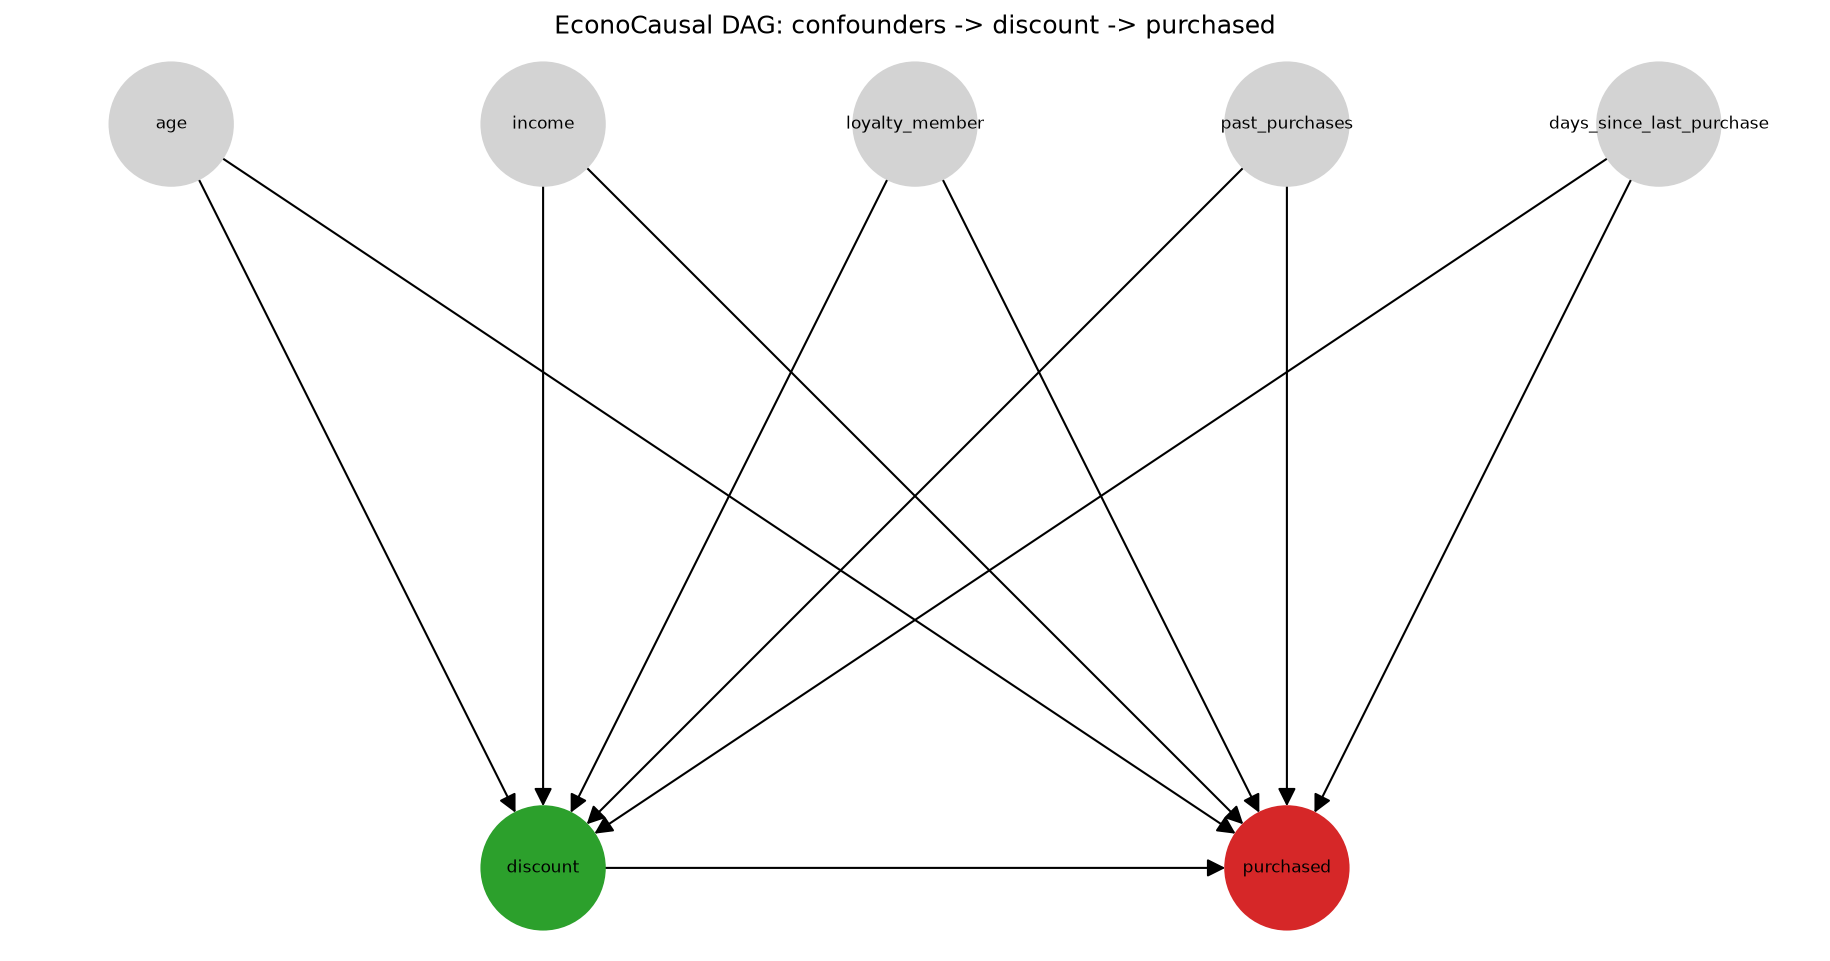

In [4]:
display(Image(filename=str(ROOT / "docs" / "causal_dag.png")))

In [5]:
def adjusted_effect(level):
    sub = df[df["discount"].isin([0, level])].copy()
    model = CausalModel(data=sub, treatment=TREATMENT, outcome=OUTCOME, graph=build_gml())
    estimand = model.identify_effect(proceed_when_unidentifiable=True)
    est = model.estimate_effect(
        estimand, method_name="backdoor.linear_regression",
        control_value=0, treatment_value=level,
    )
    return est.value

adj10 = adjusted_effect(10)
adj20 = adjusted_effect(20)
print("Adjusted effect of $10:", round(adj10, 3))
print("Adjusted effect of $20:", round(adj20, 3))

Adjusted effect of $10: 0.025
Adjusted effect of $20: 0.036


In [6]:
naive10 = rates.loc[10, "purchase_rate"] - rates.loc[0, "purchase_rate"]
naive20 = rates.loc[20, "purchase_rate"] - rates.loc[0, "purchase_rate"]

summary = pd.DataFrame({
    "Naive": [naive10, naive20],
    "Adjusted (linear)": [adj10, adj20],
    "True (synthetic)": [truth["true_uplift_10"].mean(), truth["true_uplift_20"].mean()],
}, index=["$10 discount", "$20 discount"]).round(3)
print(summary)

summary.plot(kind="bar", figsize=(8, 4), rot=0)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Effect on purchase probability")
plt.title("Naive vs adjusted vs true average effect")
plt.tight_layout()
plt.savefig(ROOT / "docs" / "naive_vs_adjusted.png", dpi=150)
plt.show()

              Naive  Adjusted (linear)  True (synthetic)
$10 discount -0.073              0.025             0.030
$20 discount -0.097              0.036             0.042


C:\Users\User\AppData\Local\Temp\ipykernel_34344\4285261292.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [7]:
print(truth["true_segment"].value_counts())
print("\nShare of customers with negative true uplift at $20:",
      round((truth["true_uplift_20"] < 0).mean(), 3))

true_segment
sleeping_dog    3543
persuadable     3494
lost_cause      2359
sure_thing       604
Name: count, dtype: int64

Share of customers with negative true uplift at $20: 0.354


## Takeaways
- The naive comparison is biased: discounts went mostly to inactive customers.
- Adjusting for confounders (backdoor criterion) recovers an effect close to the truth *on average*.
- An average hides large differences between customers: persuadables gain, sleeping dogs lose.
- Week 2: Double ML estimates the effect **per customer** (ITE), which a linear model cannot do.